# K Nearest Neighbors | Intuitive explained | Machine Learning Basics

From the Youtube video: [K Nearest Neighbors | Intuitive explained | Machine Learning Basics](https://www.youtube.com/watch?v=0p0o5cmgLdE)

In [1]:
# knn from sklearn
from sklearn import neighbors, datasets

# import some data to play with
iris = datasets.load_iris()

iris

{'data': array([[5.1, 3.5, 1.4, 0.2],
        [4.9, 3. , 1.4, 0.2],
        [4.7, 3.2, 1.3, 0.2],
        [4.6, 3.1, 1.5, 0.2],
        [5. , 3.6, 1.4, 0.2],
        [5.4, 3.9, 1.7, 0.4],
        [4.6, 3.4, 1.4, 0.3],
        [5. , 3.4, 1.5, 0.2],
        [4.4, 2.9, 1.4, 0.2],
        [4.9, 3.1, 1.5, 0.1],
        [5.4, 3.7, 1.5, 0.2],
        [4.8, 3.4, 1.6, 0.2],
        [4.8, 3. , 1.4, 0.1],
        [4.3, 3. , 1.1, 0.1],
        [5.8, 4. , 1.2, 0.2],
        [5.7, 4.4, 1.5, 0.4],
        [5.4, 3.9, 1.3, 0.4],
        [5.1, 3.5, 1.4, 0.3],
        [5.7, 3.8, 1.7, 0.3],
        [5.1, 3.8, 1.5, 0.3],
        [5.4, 3.4, 1.7, 0.2],
        [5.1, 3.7, 1.5, 0.4],
        [4.6, 3.6, 1. , 0.2],
        [5.1, 3.3, 1.7, 0.5],
        [4.8, 3.4, 1.9, 0.2],
        [5. , 3. , 1.6, 0.2],
        [5. , 3.4, 1.6, 0.4],
        [5.2, 3.5, 1.5, 0.2],
        [5.2, 3.4, 1.4, 0.2],
        [4.7, 3.2, 1.6, 0.2],
        [4.8, 3.1, 1.6, 0.2],
        [5.4, 3.4, 1.5, 0.4],
        [5.2, 4.1, 1.5, 0.1],
  

In [2]:
# we only take the first two features for demonstration
x = iris.data[:, :2]
y = iris.target

In [3]:
#print("X array")
#print(x)

#print("\nY array")
#print(y)

import pandas as pd

df_x = pd.DataFrame(x, columns=iris.feature_names[:2])
display(df_x)

,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6
...,...,...
145,6.7,3.0
146,6.3,2.5
147,6.5,3.0
148,6.2,3.4


The target class is the species of the iris flower. It can be one of three values: setosa, versicolor, or virginica.

In [4]:
df_y = pd.DataFrame(y, columns=["target"])
df_y['Flower name'] = df_y['target'].map({0: 'setosa', 1: 'versicolor', 2: 'virginica'})
display(df_y)

,target,Flower name
0,0,setosa
1,0,setosa
2,0,setosa
3,0,setosa
4,0,setosa
...,...,...
145,2,virginica
146,2,virginica
147,2,virginica
148,2,virginica


In [5]:
#number_of_neighbours_to_test = (3,15) # Just 3 and 15
number_of_neighbours_to_test = range(1, 16) # All numbers from 3 to 15
fitted_algorithms = {}

for k in number_of_neighbours_to_test:
    clf = neighbors.KNeighborsClassifier(n_neighbors=k)
    clf.fit(x, y)
    fitted_algorithms[k] = clf

Plotting the fitted algorithms

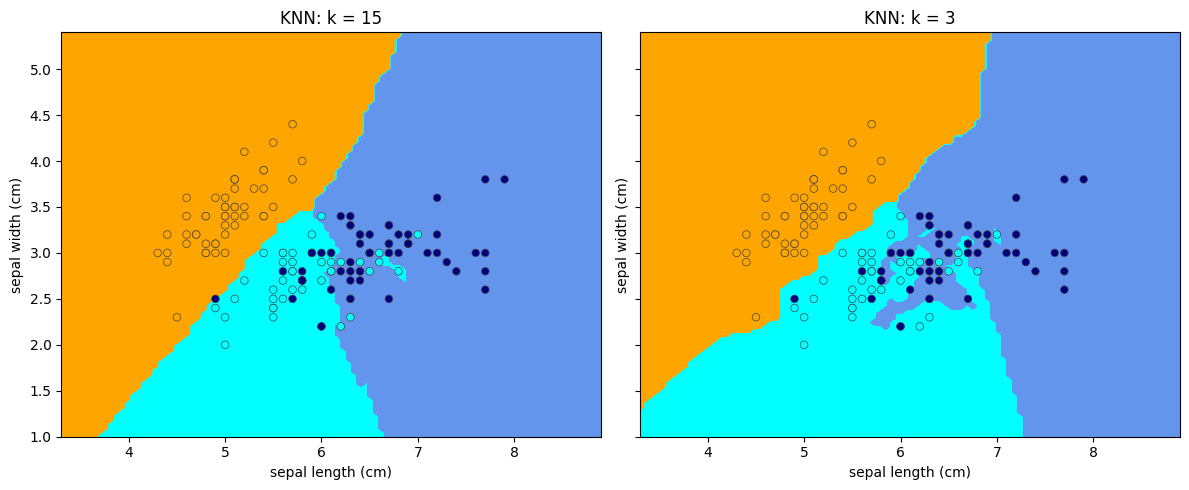

In [6]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

region_cmap = ListedColormap(["orange", "cyan", "cornflowerblue"])
point_cmap = ListedColormap(["orange", "cyan", "navy"])
use_light_colours_bool = False

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)

for ax, (k, clf) in zip(axes, ((k, fitted_algorithms[k]) for k in (15, 3))):
    if use_light_colours_bool:
        DecisionBoundaryDisplay.from_estimator(
                clf,
                x,
                response_method="predict",
                cmap="Pastel1",
                alpha=0.6,
                ax=ax,
            )

        ax.scatter(
            x[:, 0], x[:, 1],
            c=y,
            cmap="Set1",
            edgecolors="black",
            s=35,
        )
    else:
        DecisionBoundaryDisplay.from_estimator(
            clf,
            x,
            response_method="predict",
            cmap=region_cmap,
            alpha=1,
            ax=ax,
        )

        ax.scatter(
            x[:, 0], x[:, 1],
            c=y,
            cmap=point_cmap,
            vmin=0,
            vmax=2,
            edgecolors="#444444",
            linewidths=0.5,
            s=30,
        )

    ax.set_title(f"KNN: k = {k}")
    ax.set_xlabel(iris.feature_names[0])
    ax.set_ylabel(iris.feature_names[1])

plt.tight_layout()
plt.show()

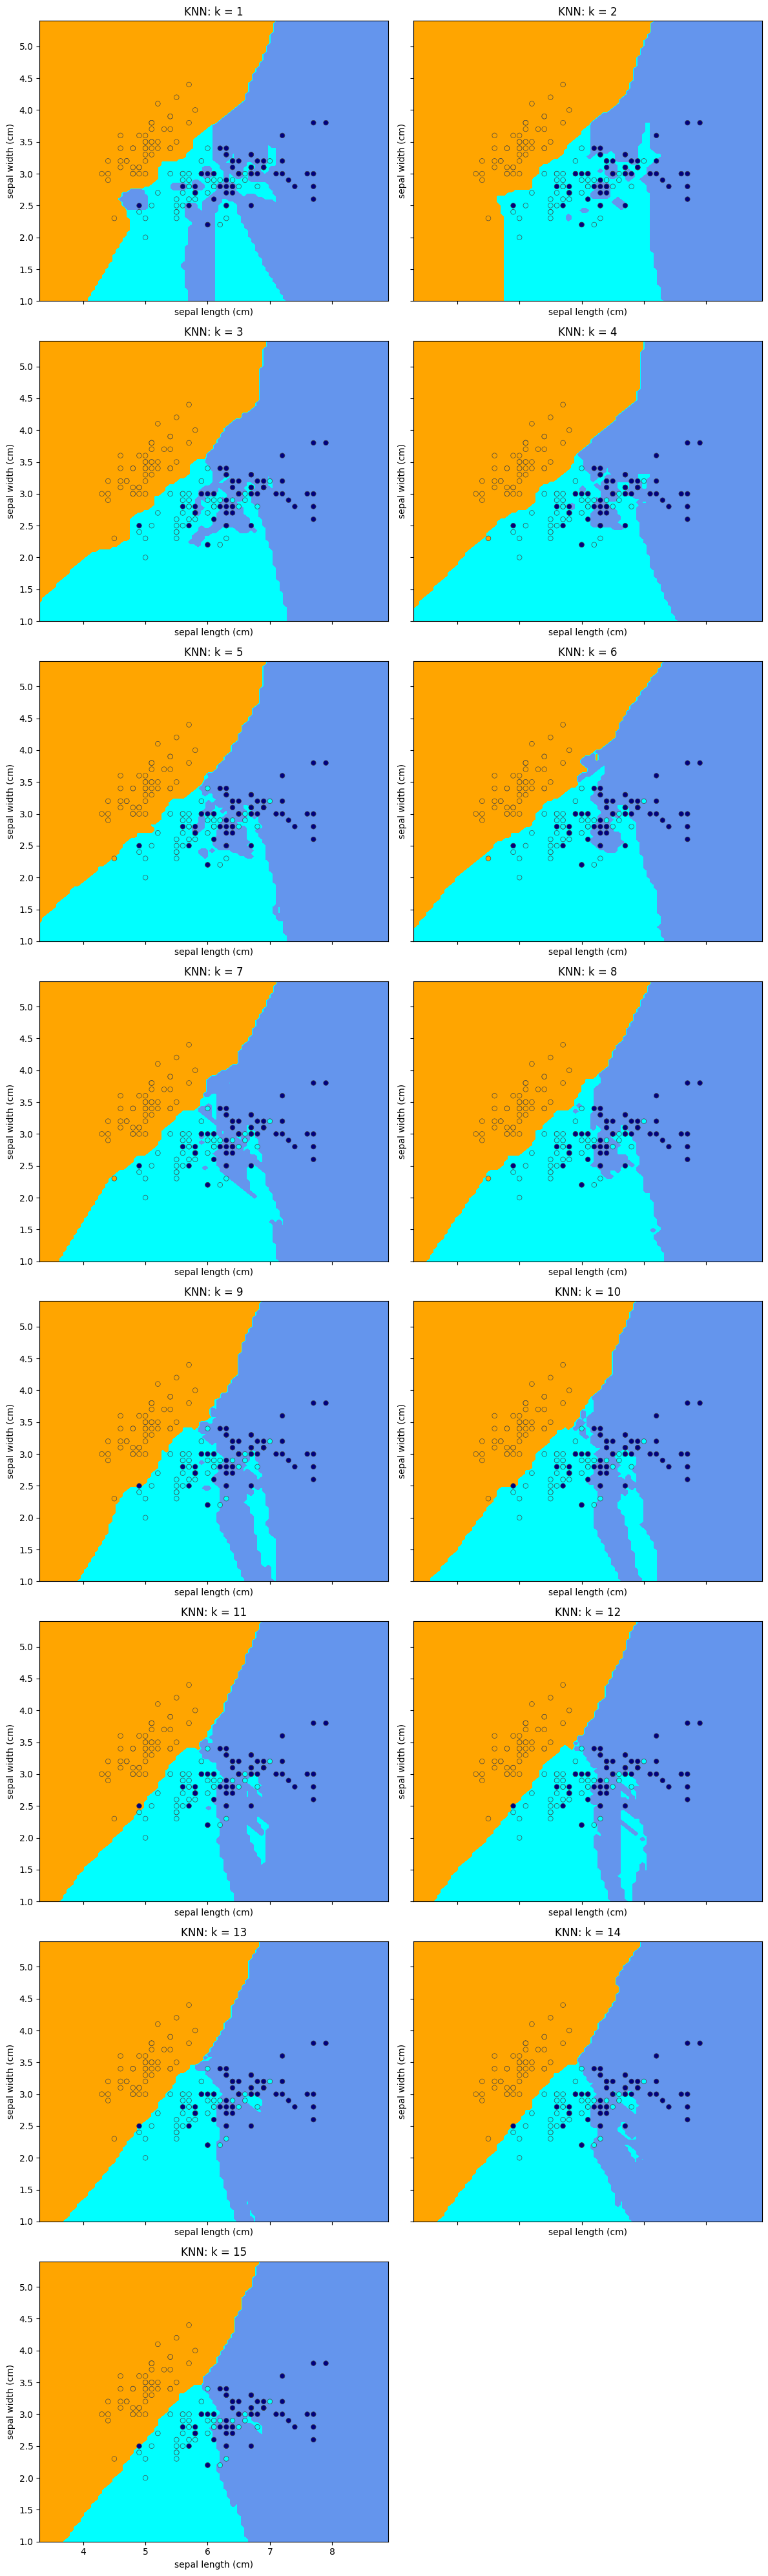

In [7]:
import math
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

n_models = len(fitted_algorithms)
n_rows = math.ceil(n_models / 2)

fig, axes = plt.subplots(
    n_rows, 2,
    figsize=(12, 5 * n_rows),
    sharex=True,
    sharey=True,
    squeeze=False,
)
axes = axes.ravel()

for ax, (k, clf) in zip(axes, fitted_algorithms.items()):
    if use_light_colours_bool:
        DecisionBoundaryDisplay.from_estimator(
            clf,
            x,
            response_method="predict",
            cmap="Pastel1",
            alpha=0.6,
            ax=ax,
        )

        ax.scatter(
            x[:, 0], x[:, 1],
            c=y,
            cmap="Set1",
            edgecolors="black",
            s=35,
        )
    else:
        DecisionBoundaryDisplay.from_estimator(
            clf,
            x,
            response_method="predict",
            cmap=region_cmap,
            alpha=1,
            ax=ax,
        )

        ax.scatter(
            x[:, 0], x[:, 1],
            c=y,
            cmap=point_cmap,
            vmin=0,
            vmax=2,
            edgecolors="#444444",
            linewidths=0.5,
            s=30,
        )

    ax.set_title(f"KNN: k = {k}")
    ax.set_xlabel(iris.feature_names[0])
    ax.set_ylabel(iris.feature_names[1])

# Hide the extra subplot when the model count is odd.
for ax in axes[n_models:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## Which algorighm performs best.

Compare their predictions on **held-out data**—samples they didn’t train on. The plots alone won’t tell you which performs best.

For this Iris example, use the same training and validation split for every value of `k`:

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

x_train, x_val, y_train, y_val = train_test_split(
    x, y,
    test_size=0.25,
    random_state=42,
    stratify=y,
)

scores = {}

for k in number_of_neighbours_to_test:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(x_train, y_train)

    predictions = clf.predict(x_val)
    scores[k] = accuracy_score(y_val, predictions)

for k, score in sorted(scores.items(), key=lambda item: item[1], reverse=True):
    print(f"k = {k:2}: validation accuracy = {score:.1%}")

k = 13: validation accuracy = 84.2%
k =  9: validation accuracy = 81.6%
k = 10: validation accuracy = 81.6%
k = 11: validation accuracy = 81.6%
k = 14: validation accuracy = 76.3%
k = 15: validation accuracy = 76.3%
k =  6: validation accuracy = 71.1%
k =  8: validation accuracy = 71.1%
k = 12: validation accuracy = 71.1%
k =  5: validation accuracy = 68.4%
k =  7: validation accuracy = 68.4%
k =  1: validation accuracy = 65.8%
k =  2: validation accuracy = 65.8%
k =  4: validation accuracy = 65.8%
k =  3: validation accuracy = 60.5%
